In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("marketing_campaign (1).csv", sep="\t")

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
df.shape

(2240, 29)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [17]:
print(df.duplicated().sum())
df["Income"] = df["Income"].fillna(df["Income"].median())

0


In [6]:
mnt_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
buy_cols = ["NumDealsPurchases","NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]

rfm = pd.DataFrame({
    "Recency": df["Recency"],
    "Frequency": df[buy_cols].sum(axis=1),
    "Monetary": df[mnt_cols].sum(axis=1)
})
rfm = rfm[rfm["Frequency"] > 0].reset_index(drop=True)
rfm.describe()

,Recency,Frequency,Monetary
count,2236.000000,2236.000000,2236.000000
mean,49.088998,14.888640,606.870751
std,28.963645,7.658227,602.253154
min,0.000000,1.000000,8.000000
25%,24.000000,8.000000,69.000000
50%,49.000000,15.000000,397.000000
75%,74.000000,21.000000,1047.250000
max,99.000000,44.000000,2525.000000


In [7]:
X = StandardScaler().fit_transform(rfm)

 K  Inertia  Silhouette
 2   3580.6       0.418
 3   2617.4       0.377
 4   1907.1       0.377
 5   1610.7       0.369
 6   1394.9       0.355
 7   1241.9       0.335
 8   1098.6       0.343
Best K by silhouette: 2


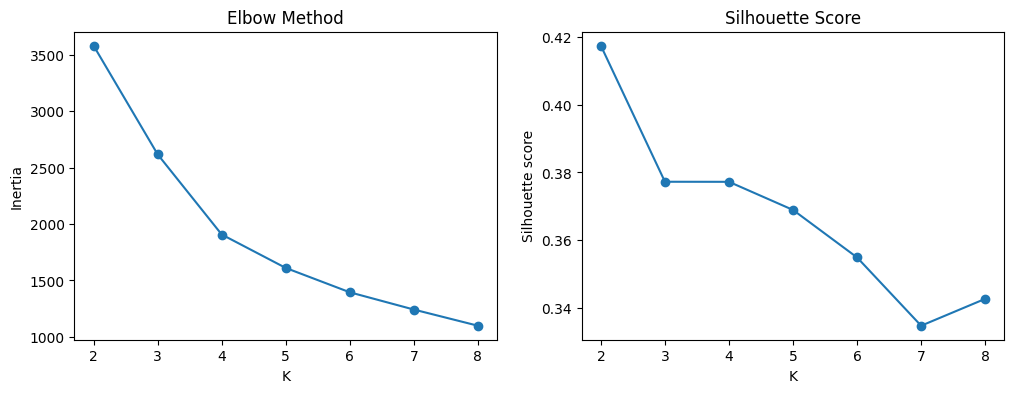

In [14]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

# Table of scores for every k
print(pd.DataFrame({"K": list(ks),
                    "Inertia": np.round(inertia, 1),
                    "Silhouette": np.round(sil, 3)}).to_string(index=False))
print("Best K by silhouette:", list(ks)[int(np.argmax(sil))])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker="o")
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sil, marker="o")
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette score")
plt.show()

In [15]:
# Try different eps values for DBSCAN
for eps in [0.2, 0.25, 0.3, 0.4, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    print(f"eps={eps}: clusters={len(set(labels)) - (1 if -1 in labels else 0)}, noise={(labels == -1).sum()}")

K = 4
rfm["KMeans"] = KMeans(n_clusters=K, random_state=42, n_init=10).fit_predict(X)
rfm["DBSCAN"] = DBSCAN(eps=0.3, min_samples=10).fit_predict(X)     # was 0.5

print(rfm["KMeans"].value_counts().sort_index())
print(rfm["DBSCAN"].value_counts().sort_index())

print("K-Means silhouette:", round(silhouette_score(X, rfm["KMeans"]), 3))
mask = rfm["DBSCAN"] != -1
if rfm.loc[mask, "DBSCAN"].nunique() > 1:
    print("DBSCAN silhouette (without noise):", round(silhouette_score(X[mask], rfm.loc[mask, "DBSCAN"]), 3))


eps=0.2: clusters=10, noise=1060
eps=0.25: clusters=15, noise=686
eps=0.3: clusters=9, noise=291
eps=0.4: clusters=1, noise=100
eps=0.5: clusters=1, noise=28
KMeans
0    605
1    552
2    502
3    577
Name: count, dtype: int64
DBSCAN
-1     291
 0    1625
 1     176
 2      30
 3      63
 4      13
 5      15
 6      10
 7       7
 8       6
Name: count, dtype: int64
K-Means silhouette: 0.377
DBSCAN silhouette (without noise): -0.014


In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("PCA variance explained:", pca.explained_variance_ratio_.round(3))

X_tsne = TSNE(n_components=2, perplexity=30, init="pca",
              learning_rate="auto", random_state=42).fit_transform(X)

PCA variance explained: [0.585 0.333]


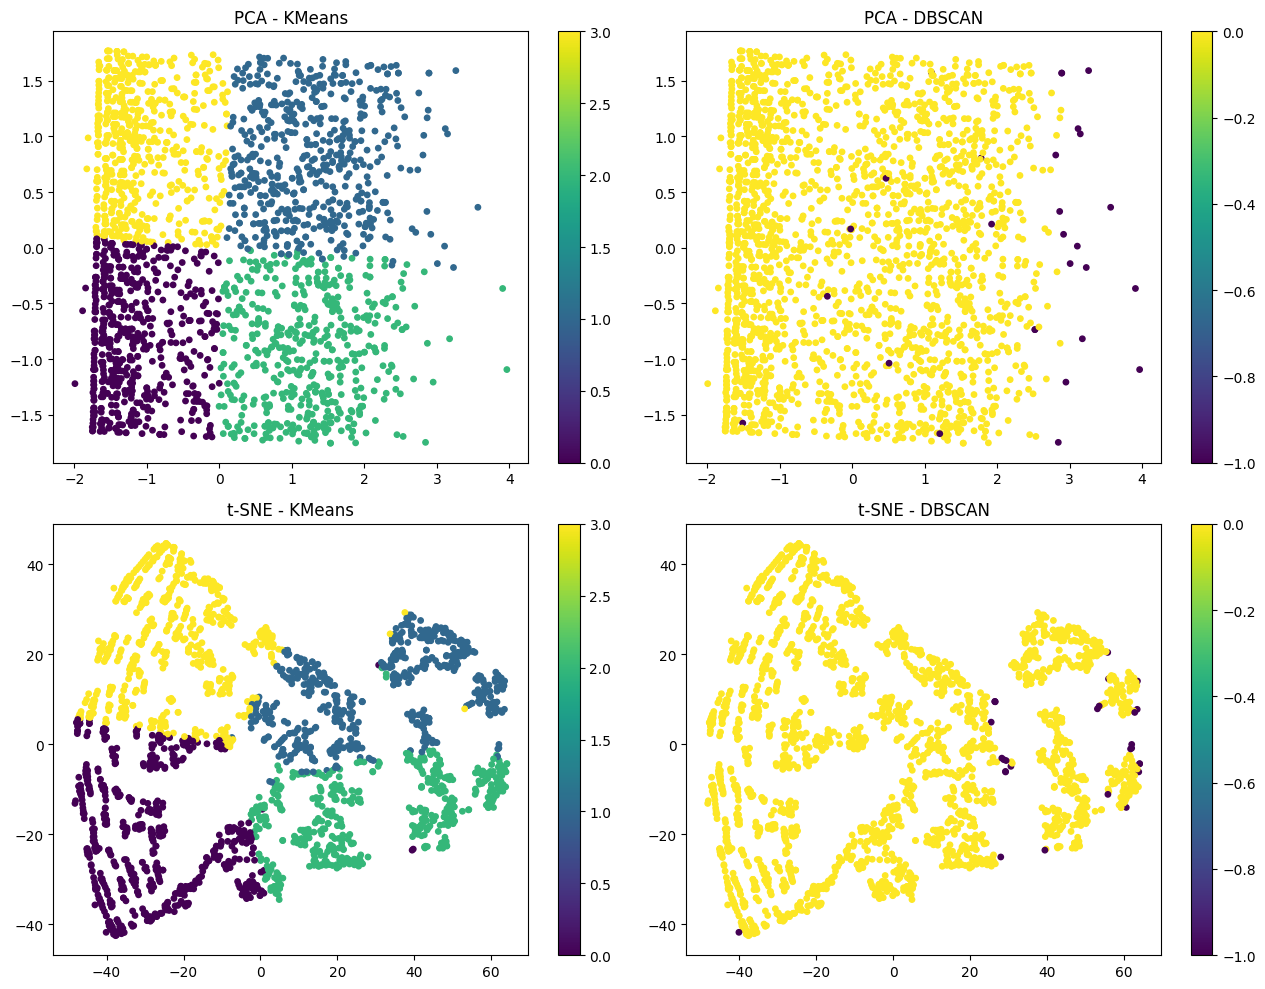

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (name, emb) in enumerate([("PCA", X_pca), ("t-SNE", X_tsne)]):
    for col, algo in enumerate(["KMeans", "DBSCAN"]):
        sc = axes[row, col].scatter(emb[:, 0], emb[:, 1], c=rfm[algo], cmap="viridis", s=15)
        axes[row, col].set_title(f"{name} - {algo}")
        plt.colorbar(sc, ax=axes[row, col])
plt.tight_layout()
plt.show()

In [13]:
profile = rfm.groupby("KMeans").agg(
    Customers=("Monetary", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(1)

def persona(r):
    hi_m = r.Avg_Monetary >= profile.Avg_Monetary.median()
    hi_f = r.Avg_Frequency >= profile.Avg_Frequency.median()
    recent = r.Avg_Recency <= profile.Avg_Recency.median()
    if hi_m and hi_f and recent:
        return "Champions", "Loyalty program, early access, referral rewards"
    if hi_m and hi_f:
        return "Loyal but Cooling", "Personalized win-back emails, 'we miss you' offers"
    if hi_m:
        return "Big Spenders", "Premium bundles, upsell and cross-sell"
    if recent:
        return "New / Promising", "Welcome series, nudge for second purchase"
    return "At-Risk / Low Value", "Discount reactivation, low-cost email only"

profile["Persona"], profile["Marketing Action"] = zip(*profile.apply(persona, axis=1))
profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing Action
KMeans,,,,,,
0,605,24.6,8.6,127.7,New / Promising,"Welcome series, nudge for second purchase"
1,552,72.8,21.5,1158.7,Loyal but Cooling,"Personalized win-back emails, 'we miss you' of..."
2,502,22.9,21.9,1115.1,Champions,"Loyalty program, early access, referral rewards"
3,577,74.9,9.0,139.2,At-Risk / Low Value,"Discount reactivation, low-cost email only"
